# SpamJam: data exploration

SpamJam helps GrandPied's IT team flag spam (`is_spam` = 1) while protecting legitimate emails (`is_spam` = 0). The problem and the cost of each mistake are described in the README and used in `analysis.ipynb` to choose our metric and threshold.

We load the Spambase dataset (UCI, id 94) through our package. The first run downloads it and saves it, and then later runs read that file. We then remove duplicates, split the data into a training and a test set, and explore the training set only.

In [40]:
import matplotlib.pyplot as plt
from spamjam.data import DatasetLoader
import logging
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import spamjam.constants as constants
import numpy as np

logging.basicConfig(level=logging.INFO)
pd.set_option("display.max_columns", None)

#loading
loader = DatasetLoader.from_config()
df = loader.load_data()

df.shape

INFO:spamjam.data:Reading C:\Users\sheil\PycharmProjects\spamjam\data\raw\spambase.csv


(4601, 58)

## Duplicates

In [41]:
df_clean = loader.remove_duplicates(df)

INFO:spamjam.data:Removed 391 duplicate rows


## Train / test split

In [42]:
train_df, test_df = loader.split(df_clean)
loader.save_split(train_df, test_df)

print("SPLIT VERIFICATION")
print(f"Train: {train_df.shape}, spam {train_df['is_spam'].mean():.2%}")
print(f"Test:  {test_df.shape}, spam {test_df['is_spam'].mean():.2%}")

INFO:spamjam.data:Saved C:\Users\sheil\PycharmProjects\spamjam\data\processed\train.csv and C:\Users\sheil\PycharmProjects\spamjam\data\processed\test.csv


SPLIT VERIFICATION
Train: (3368, 58), spam 39.88%
Test:  (842, 58), spam 39.90%


We split once, stratified, and save both sets. From here on we only use the training set; the test set is used once, at the end.

## Columns and types

In [43]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3368 entries, 436 to 3242
Data columns (total 58 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   word_freq_make              3368 non-null   float64
 1   word_freq_address           3368 non-null   float64
 2   word_freq_all               3368 non-null   float64
 3   word_freq_3d                3368 non-null   float64
 4   word_freq_our               3368 non-null   float64
 5   word_freq_over              3368 non-null   float64
 6   word_freq_remove            3368 non-null   float64
 7   word_freq_internet          3368 non-null   float64
 8   word_freq_order             3368 non-null   float64
 9   word_freq_mail              3368 non-null   float64
 10  word_freq_receive           3368 non-null   float64
 11  word_freq_will              3368 non-null   float64
 12  word_freq_people            3368 non-null   float64
 13  word_freq_report            3368 non

In [44]:
train_df["is_spam"].value_counts().sort_index()

is_spam
0    2025
1    1343
Name: count, dtype: int64

All 57 features are numeric (word and character frequencies, and capital-letter run lengths), and the target `is_spam` is 0 (ham) or 1 (spam).

## Missing values

In [45]:
train_df.isna().sum().sum()

np.int64(0)

There are no missing values, so no imputation is needed.

## Value ranges and special codes

In [46]:
train_df.describe()

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,word_freq_receive,word_freq_will,word_freq_people,word_freq_report,word_freq_addresses,word_freq_free,word_freq_business,word_freq_email,word_freq_you,word_freq_credit,word_freq_your,word_freq_font,word_freq_000,word_freq_money,word_freq_hp,word_freq_hpl,word_freq_george,word_freq_650,word_freq_lab,word_freq_labs,word_freq_telnet,word_freq_857,word_freq_data,word_freq_415,word_freq_85,word_freq_technology,word_freq_1999,word_freq_parts,word_freq_pm,word_freq_direct,word_freq_cs,word_freq_meeting,word_freq_original,word_freq_project,word_freq_re,word_freq_edu,word_freq_table,word_freq_conference,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,is_spam
count,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.00000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000,3368.000000
mean,0.100383,0.117307,0.295632,0.043999,0.328002,0.096274,0.114017,0.105638,0.093337,0.253171,0.055324,0.553183,0.098355,0.062613,0.047726,0.25747,0.148774,0.189498,1.717542,0.080214,0.801781,0.143729,0.100698,0.089403,0.564602,0.280404,0.379596,0.129902,0.095992,0.101666,0.066235,0.046018,0.103979,0.047093,0.107640,0.098946,0.145270,0.016384,0.089385,0.060698,0.038406,0.138714,0.052313,0.080980,0.313916,0.178109,0.005338,0.032717,0.040720,0.146209,0.017479,0.285949,0.077270,0.046897,5.194729,52.078088,288.178444,0.398753
std,0.294424,0.485718,0.527413,1.132665,0.704859,0.284575,0.384393,0.410446,0.290937,0.690361,0.181465,0.848085,0.320621,0.368328,0.255024,0.78754,0.454326,0.555320,1.767574,0.415134,1.137508,1.138226,0.355879,0.441824,1.630888,0.912027,1.837381,0.541533,0.575262,0.421975,0.402012,0.308639,0.529811,0.309930,0.543801,0.377232,0.431231,0.255651,0.474324,0.319597,0.286796,0.770725,0.245015,0.547433,1.010119,0.874063,0.075136,0.266608,0.250978,0.289317,0.108179,0.857139,0.250516,0.452181,29.886375,211.727626,631.485389,0.489714
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.611000,7.000000,39.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.165000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,1.370000,0.000000,0.290000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000

No value is negative, and there are no strange codes like -1 or 999. A 0 simply means the word or character isn't in the email, so it's a real value, not missing data. Most emails have 0 for most words.

The features have very different sizes. Word and character frequencies are small numbers (usually between 0 and a few percent), while the capital-letter features are much bigger (for example, an email has about 288 capital letters on average). Some models would treat the big numbers as more important just because they're bigger, so we will scale all features to the same range in the pipeline.

## First rows

In [47]:
train_df.head()

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,word_freq_receive,word_freq_will,word_freq_people,word_freq_report,word_freq_addresses,word_freq_free,word_freq_business,word_freq_email,word_freq_you,word_freq_credit,word_freq_your,word_freq_font,word_freq_000,word_freq_money,word_freq_hp,word_freq_hpl,word_freq_george,word_freq_650,word_freq_lab,word_freq_labs,word_freq_telnet,word_freq_857,word_freq_data,word_freq_415,word_freq_85,word_freq_technology,word_freq_1999,word_freq_parts,word_freq_pm,word_freq_direct,word_freq_cs,word_freq_meeting,word_freq_original,word_freq_project,word_freq_re,word_freq_edu,word_freq_table,word_freq_conference,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,is_spam
436,0.0,0.0,0.00,0.0,0.00,0.05,0.00,0.34,0.0,0.00,0.11,0.81,0.05,0.11,0.0,0.00,0.75,0.0,0.00,0.0,0.00,0.0,0.05,0.00,1.16,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.05,0.00,0.00,0.23,0.05,0.0,0.00,0.00,0.0,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.283,0.107,0.000,0.000,0.053,0.0,1.864,32,910,1
1032,0.0,0.0,0.48,0.0,0.96,0.00,0.48,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.0,0.48,0.96,0.0,1.92,0.0,1.44,0.0,0.48,0.48,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.0,1.44,0.0,0.0,0.0,0.000,0.073,0.000,0.515,0.957,0.0,6.833,78,328,1
1803,0.0,0.0,0.00,0.0,0.00,0.00,0.00,0.00,0.0,0.00,0.00,1.38,0.00,0.00,0.0,0.00,0.00,0.0,1.38,0.0,1.38,0.0,0.00,0.00,1.38,1.38,2.77,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.38,0.0,1.38,0.00,0.0,0.0,1.38,0.0,0.00,0.0,0.0,0.0,0.000,0.000,0.224,0.448,0.000,0.0,1.451,12,45,0
3504,0.0,0.0,0.00,0.0,0.88,0.00,0.00,0.00,0.0,2.65,0.88,0.00,0.00,0.00,0.0,0.00,0.00,0.0,1.76,0.0,0.00,0.0,0.00,0.00,1.76,0.88,1.76,0.88,0.88,0.88,0.88,0.88,0.00,0.88,0.88,0.88,0.88,0.0,0.88,0.88,0.0,0.0,0.88,0.0,2.65,0.0,0.0,0.0,0.142,0.855,0.000,0.285,0.000,0.0,1.777,12,80,0
2056,0.0,0.0,0.00,0.0,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.72,0.00,0.00,0.0,0.00,0.00,0.0,1.45,0.0,2.18,0.0,0.00,0.00,1.45,0.72,1.45,0.72,0.72,0.72,0.72,0.72,0.00,0.72,0.72,0.72,0.72,0.0,0.72,0.72,0.0,0.0,0.72,0.0,0.72,0.0,0.0,0.0,0.000,0.367,0.000,0.000,0.000,0.0,1.897,12,74,0


## Leakage

All features come from the email's text, so we know them as soon as the email arrives, before anyone decides if it's spam. No feature gives away the answer, so we don't need to remove any.

One limit: the dataset has no dates, so we can't tell when each email was sent and can't check for time-based leakage. Our split is random, so the test set is not "future" emails compared to the training set. In real use, the model would always predict on newer emails than it was trained on, and spam changes over time (new words, new tricks). The data is also from around 1999 (UCI). So our test score may be more optimistic than how the model would perform on GrandPied's emails today.

## Target distribution

Proportion of spam: 39.88%


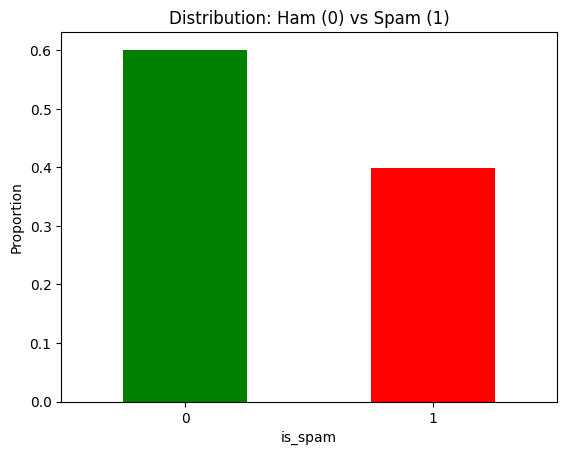

In [48]:
y = train_df["is_spam"]
print(f"Proportion of spam: {y.mean():.2%}")

y.value_counts(normalize=True).sort_index().plot(kind="bar", color=["green", "red"])
plt.title("Distribution: Ham (0) vs Spam (1)")
plt.ylabel("Proportion")
plt.xticks(rotation=0)
plt.show()

About 39% of emails are spam. The classes do not have the same amount of data so we have to ensure that when separating the data into the train and test sets we use stratify to ensure that the same proportion of the different classes exist in both the train and test sets.

## WHICH FEATURES SHOULD WE KEEP?

## **Data preparation**

In [49]:
X_train = train_df.drop(columns=['is_spam'])
y_train = train_df['is_spam']

## **Data scaling**

In [50]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

## **Fit L1 and L2**


In [51]:
lasso = LogisticRegression(penalty='l1', solver='liblinear', C=0.1, random_state=constants.RANDOM_STATE)
ridge = LogisticRegression(penalty='l2', solver='liblinear', C=0.1, random_state=constants.RANDOM_STATE)

lasso.fit(X_train_scaled, y_train)
ridge.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,0.1
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'liblinear'
,max_iter,100
,multi_class,'deprecated'


## **Create a Dataframe with the results**

In [52]:
coef_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Lasso (L1)': lasso.coef_[0],
    'Ridge (L2)': ridge.coef_[0]
})


## **L1 and L2 results**

In [53]:
print(" Feature Coefficients  ")
display(coef_df)

 Feature Coefficients  


,Feature,Lasso (L1),Ridge (L2)
0,word_freq_make,0.000000,0.006092
1,word_freq_address,0.019437,0.034766
2,word_freq_all,0.038000,0.068043
3,word_freq_3d,0.122209,0.347156
4,word_freq_our,0.278011,0.304764
5,word_freq_over,0.123625,0.140742
6,word_freq_remove,1.041036,0.984061
7,word_freq_internet,0.212908,0.238478
8,word_freq_order,0.068639,0.101251
9,word_freq_mail,0.024662,0.046416


## **Get the absolute values of the coefficients**
 We use *np.abs()* because we care about the magnitude, not the sign

In [54]:
lasso_abs_coefs = np.abs(lasso.coef_[0])
ridge_abs_coefs = np.abs(ridge.coef_[0])

## **Descriptive Statistics of Absolute L1 and L2**

In [55]:
coef_stats = pd.DataFrame({
    'Lasso (L1)': lasso_abs_coefs,
    'Ridge (L2)': ridge_abs_coefs
})
stats_df = coef_stats.describe()
display(stats_df)

,Lasso (L1),Ridge (L2)
count,57.000000,57.000000
mean,0.284509,0.342146
std,0.388501,0.316418
min,0.000000,0.006092
25%,0.038000,0.104209
50%,0.130746,0.245939
75%,0.326421,0.429078
max,1.815426,1.465359


## **Thresholds of L1 and L2**
Here we took the first quartile as the threshold for each of them

In [56]:
threshold_lasso = stats_df.loc['25%', 'Lasso (L1)']
threshold_ridge = stats_df.loc['25%', 'Ridge (L2)']

print(f"Calculated Threshold for Lasso (25th percentile): {threshold_lasso:.4f}")
print(f"Calculated Threshold for Ridge (25th percentile): {threshold_ridge:.4f}")

Calculated Threshold for Lasso (25th percentile): 0.0380
Calculated Threshold for Ridge (25th percentile): 0.1042


## **Apply thresholds to keep only the important features**

In [57]:
features_kept_lasso = X_train.columns[lasso_abs_coefs > 0]
features_kept_ridge = X_train.columns[ridge_abs_coefs > threshold_ridge]

print(f"\nLasso kept {len(features_kept_lasso)} features (Threshold = 0)")
print(f"Ridge kept {len(features_kept_ridge)} features (Threshold = {threshold_ridge:.4f})")



Lasso kept 50 features (Threshold = 0)
Ridge kept 42 features (Threshold = 0.1042)
